# Inferencia estadística y pruebas de hipótesis

Casi siempre trabajamos con una muestra y queremos sacar conclusiones sobre la población de la que proviene. Ese proceso se llama inferencia estadística y tiene tres formas: la estimación puntual, que resume un parámetro con un solo valor; la estimación por intervalos, que da un rango de valores con un nivel de confianza; y la prueba de hipótesis, que evalúa la evidencia que aporta la muestra en contra de una afirmación sobre la población {cite}`wasserman2004`.

## Estimación puntual e intervalos de confianza

Si se tomara otra muestra del mismo tamaño, la estimación puntual cambiaría. La estimación por intervalos tiene en cuenta esa incertidumbre: combina la estimación puntual con su error estándar. Para la media, con una muestra grande, el intervalo de confianza del 95 % es aproximadamente $\bar x \pm 1.96\, s/\sqrt{n}$. Su interpretación correcta es frecuentista: si se repitiera el muestreo muchas veces, el 95 % de los intervalos construidos así contendría la media verdadera. La celda siguiente lo verifica por simulación.

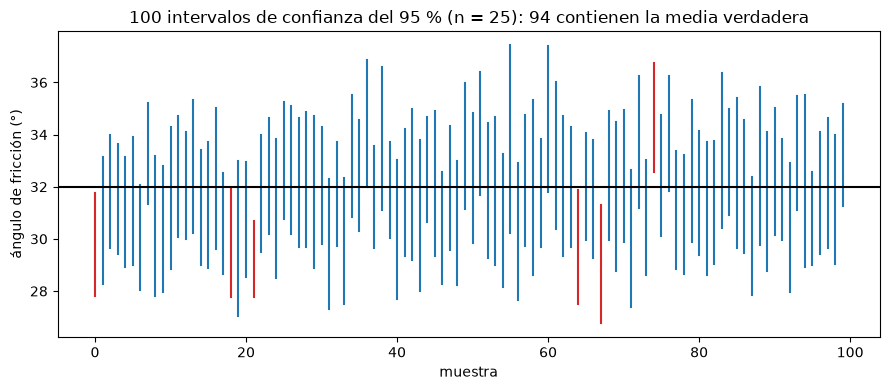

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
plt.rcParams['figure.dpi'] = 100
rng = np.random.default_rng(7)

mu, sigma, n = 32.0, 6.0, 25        # ángulo de fricción "verdadero" de una unidad (°) y su variabilidad
cubre = 0
fig, ax = plt.subplots(figsize=(9, 4))
for i in range(100):
    m = rng.normal(mu, sigma, n)
    t = stats.t.ppf(0.975, n - 1)
    lo, hi = m.mean() - t * m.std(ddof=1) / np.sqrt(n), m.mean() + t * m.std(ddof=1) / np.sqrt(n)
    ok = lo <= mu <= hi; cubre += ok
    ax.plot([i, i], [lo, hi], color='tab:blue' if ok else 'tab:red')
ax.axhline(mu, color='k'); ax.set_xlabel('muestra'); ax.set_ylabel('ángulo de fricción (°)')
ax.set_title(f'100 intervalos de confianza del 95 % (n = {n}): {cubre} contienen la media verdadera')
plt.tight_layout(); plt.show()

## El bootstrap

Cuando no hay una fórmula para el error estándar de un estadístico, o cuando sus supuestos no se cumplen, se usa el bootstrap {cite}`efron1979`. Se remuestrea la muestra observada con reemplazo muchas veces, se calcula el estadístico en cada remuestra y la distribución de esos valores aproxima la distribución muestral del estadístico. Los percentiles 2.5 y 97.5 de esa distribución dan un intervalo de confianza del 95 %. El bootstrap hace pocos supuestos, pero funciona mal con muestras muy pequeñas. La celda siguiente lo aplica a la mediana del área de deslizamientos, una variable con distribución lognormal.

Mediana del área: 761 m²; IC 95 % bootstrap: [569, 1298] m²


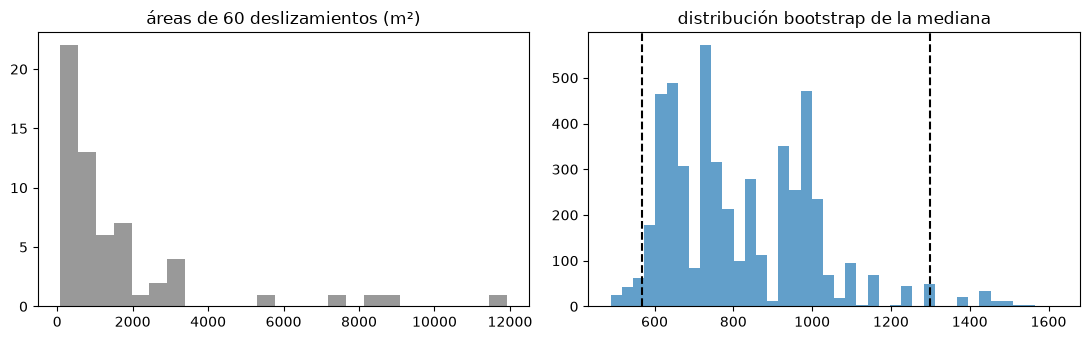

In [2]:
areas = rng.lognormal(mean=np.log(900), sigma=1.1, size=60)    # m²
boot = np.array([np.median(rng.choice(areas, areas.size)) for _ in range(5000)])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'Mediana del área: {np.median(areas):.0f} m²; IC 95 % bootstrap: [{lo:.0f}, {hi:.0f}] m²')
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(areas, bins=25, color='0.6'); ax[0].set_title('áreas de 60 deslizamientos (m²)')
ax[1].hist(boot, bins=40, color='tab:blue', alpha=0.7); ax[1].axvline(lo, color='k', ls='--'); ax[1].axvline(hi, color='k', ls='--')
ax[1].set_title('distribución bootstrap de la mediana')
plt.tight_layout(); plt.show()

## Pruebas de hipótesis

Una prueba de hipótesis compara dos afirmaciones excluyentes sobre la población: la hipótesis nula $H_0$, que suele expresar ausencia de efecto o de diferencia, y la alternativa $H_1$. Con los datos se calcula un estadístico de prueba y su valor p, la probabilidad de obtener un resultado al menos tan extremo como el observado si $H_0$ fuera cierta. Si el valor p es menor que el nivel de significancia $\alpha$ fijado de antemano (usualmente 0.05), se rechaza $H_0$. Una prueba no demuestra que $H_1$ sea cierta: evalúa la fuerza de la evidencia en contra de $H_0$. Rechazar $H_0$ siendo cierta es un error de tipo I, cuya probabilidad es $\alpha$; no rechazarla siendo falsa es un error de tipo II.

Si se conoce la distribución de los datos, o es aproximadamente normal, se usan pruebas paramétricas: la prueba t para comparar la media de una muestra con un valor o las medias de dos muestras (con su variante de Welch para varianzas distintas y la pareada para muestras emparejadas), y el ANOVA para comparar más de dos grupos. Si no, se usan pruebas no paramétricas, que trabajan con rangos: la de Mann-Whitney (o suma de rangos de Wilcoxon) para dos muestras independientes, la de rangos con signo de Wilcoxon para muestras pareadas y la de Kruskal-Wallis para más de dos grupos.

La celda siguiente aplica estas pruebas a una pregunta típica de la selección de variables: ¿difiere la pendiente de los sitios con y sin deslizamiento? ¿y la curvatura?

In [3]:
n0, n1 = 400, 120
pend0, pend1 = rng.gamma(4, 6, n0), rng.gamma(4, 6, n1) + 6            # los deslizamientos ocurren en pendientes algo mayores
curv0, curv1 = rng.normal(0, 1, n0), rng.normal(-0.1, 1, n1)            # diferencia muy pequeña
for nom, a, b in [('pendiente', pend0, pend1), ('curvatura', curv0, curv1)]:
    t = stats.ttest_ind(a, b, equal_var=False)
    u = stats.mannwhitneyu(a, b)
    smd = abs(a.mean() - b.mean()) / np.sqrt((a.var(ddof=1) + b.var(ddof=1)) / 2)
    print(f'{nom:10s} t de Welch p = {t.pvalue:.2e}   Mann-Whitney p = {u.pvalue:.2e}   diferencia estandarizada = {smd:.2f}')

pendiente  t de Welch p = 2.51e-05   Mann-Whitney p = 4.27e-06   diferencia estandarizada = 0.45
curvatura  t de Welch p = 6.08e-01   Mann-Whitney p = 9.72e-01   diferencia estandarizada = 0.05


La pendiente difiere claramente entre los dos grupos. Para la curvatura el resultado depende de la muestra: con un efecto tan pequeño, el valor p puede quedar por encima o por debajo de 0.05 según la semilla. Por eso conviene reportar también una medida del tamaño del efecto, como la diferencia de medias estandarizada (SMD), que no depende del tamaño de la muestra; valores menores que 0.1 se consideran diferencias pequeñas.

## Significancia estadística no es importancia práctica

Con muestras muy grandes cualquier diferencia, por pequeña que sea, resulta significativa. La celda siguiente repite la comparación de la curvatura con muestras cada vez más grandes: el tamaño del efecto se mantiene, pero el valor p cae por debajo de cualquier umbral. En aprendizaje automático, con miles o millones de datos, las pruebas de significancia aportan poco para seleccionar variables; importan más el tamaño del efecto y el desempeño predictivo en datos independientes.

In [4]:
for n in [100, 1000, 10000, 100000]:
    a, b = rng.normal(0, 1, n), rng.normal(-0.05, 1, n)
    print(f'n = {n:6d}   p = {stats.ttest_ind(a, b).pvalue:.3g}   SMD = {abs(a.mean()-b.mean())/np.sqrt((a.var()+b.var())/2):.3f}')

n =    100   p = 0.711   SMD = 0.053
n =   1000   p = 0.0676   SMD = 0.082
n =  10000   p = 0.00013   SMD = 0.054
n = 100000   p = 1.27e-30   SMD = 0.051


## Para profundizar

Los capítulos 6 a 10 de {cite}`wasserman2004` desarrollan la inferencia frecuentista, el bootstrap y las pruebas de hipótesis. El notebook 06 del curso aplica el bootstrap, la prueba t, la diferencia estandarizada y la prueba de Wilcoxon a un inventario real de deslizamientos.